In [1]:
import random

random.seed(1000)

merek_ban = ["A", "B", "C", "D"]
jenis_mobil = ["I", "II", "III", "IV"]

for b in jenis_mobil:
  urutan = random.sample(merek_ban, len(merek_ban))
  print(f"Jenis Mobil {b} : {urutan}")

Jenis Mobil I : ['D', 'C', 'A', 'B']
Jenis Mobil II : ['C', 'A', 'B', 'D']
Jenis Mobil III : ['D', 'A', 'C', 'B']
Jenis Mobil IV : ['C', 'D', 'B', 'A']


In [2]:
import pandas as pd

data = {
    'merek_ban':['A','A','A','A','B','B','B','B','C','C','C','C','D','D','D','D'],
    'jenis_mobil':['I','II','III','IV','I','II','III','IV','I','II','III','IV','I','II','III','IV'],
    'tingkat_keausan':[17,14,13,13,14,14,13,8,12,12,10,9,13,11,11,9]
}

df = pd.DataFrame(data)
df

,merek_ban,jenis_mobil,tingkat_keausan
0,A,I,17
1,A,II,14
2,A,III,13
3,A,IV,13
4,B,I,14
5,B,II,14
6,B,III,13
7,B,IV,8
8,C,I,12
9,C,II,12


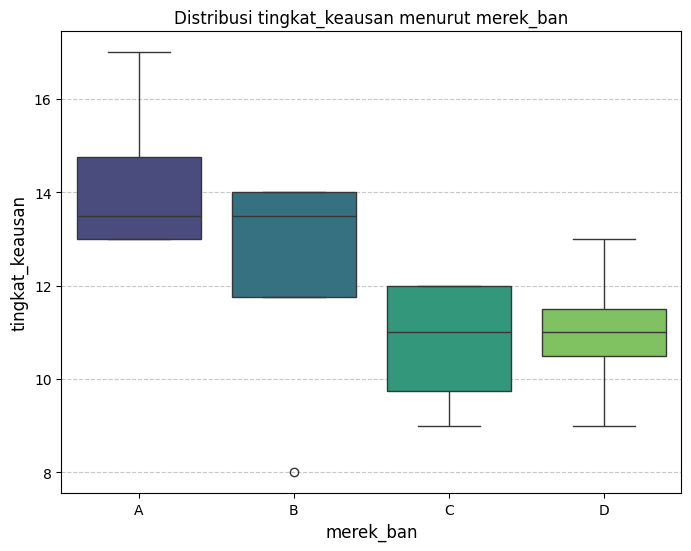

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(x='merek_ban', y='tingkat_keausan', data=df, palette='viridis', hue='merek_ban', legend=False)
plt.title('Distribusi tingkat_keausan menurut merek_ban')
plt.xlabel('merek_ban', fontsize=12)
plt.ylabel('tingkat_keausan', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [4]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

# Mengubah model utama agar hanya menganallsis faktor merek ban
model = ols('tingkat_keausan ~ C(merek_ban)+C(jenis_mobil)', data=df).fit()
anova_table1 = anova_lm(model, typ=1)
anova_table2 = anova_lm(model, typ=2)
anova_table3 = anova_lm(model, typ=3)

print(anova_table1)
print(anova_table2)
print(anova_table3)

                 df   sum_sq    mean_sq          F    PR(>F)
C(merek_ban)    3.0  30.6875  10.229167   7.962162  0.006685
C(jenis_mobil)  3.0  38.6875  12.895833  10.037838  0.003133
Residual        9.0  11.5625   1.284722        NaN       NaN
                 sum_sq   df          F    PR(>F)
C(merek_ban)    30.6875  3.0   7.962162  0.006685
C(jenis_mobil)  38.6875  3.0  10.037838  0.003133
Residual        11.5625  9.0        NaN       NaN
                  sum_sq   df           F        PR(>F)
Intercept       598.9375  1.0  466.200000  4.616571e-09
C(merek_ban)     30.6875  3.0    7.962162  6.684942e-03
C(jenis_mobil)   38.6875  3.0   10.037838  3.133358e-03
Residual         11.5625  9.0         NaN           NaN


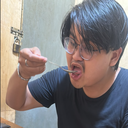

In [5]:
from IPython.display import Image, display
import base64

img_b64 = '...'
img_bytes = base64.b64decode(img_b64)
display(Image(data=img_bytes))

In [6]:
# Menghitung Cook's Distance
influence = model.get_influence()
cooks_d, p_values = influence.cooks_distance

# Memasukkan nilai Cook's Distance ke dalam DataFrame baru untuk analisis
df_cook = df.copy()
df_cook['Cooks_Distance'] = cooks_d

# Kriteria umum Cook's Distance > 4/n
n = len(df)
threshold = 4 / n

print(f"\n=== Analisis Cook's Distance (Threshold = 4/n = {threshold:.4f}) ===")
print(df_cook[['merek_ban', 'jenis_mobil', 'tingkat_keausan', 'Cooks_Distance']])

# Menunjukkan observasi yang berpotensi berpengaruh tinggi (influential points)
influential_points = df_cook[df_cook['Cooks_Distance'] > threshold]
print("\n=== Observasi Berpengaruh (Cook's Distance > Threshold) ===")
if len(influential_points) > 0:
    print(influential_points)
else:
    print("Tidak ada data observasi yang melebihi ambang batas Cook's Distance.")


=== Analisis Cook's Distance (Threshold = 4/n = 0.2500) ===
   merek_ban jenis_mobil  tingkat_keausan  Cooks_Distance
0          A           I               17        0.101502
1          A          II               14        0.135135
2          A         III               13        0.135135
3          A          IV               13        0.173574
4          B           I               14        0.005405
5          B          II               14        0.173574
6          B         III               13        0.173574
7          B          IV                8        0.577177
8          C           I               12        0.072673
9          C          II               12        0.048649
10         C         III               10        0.029429
11         C          IV                9        0.048649
12         D           I               13        0.000601
13         D          II               11        0.072673
14         D         III               11        0.015015
15         

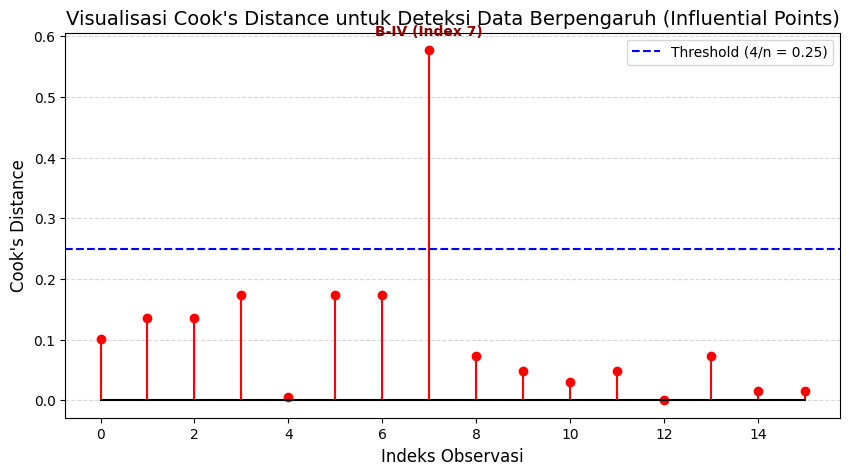

In [7]:
import matplotlib.pyplot as plt

# Membuat plot visualisasi Cook's Distance
plt.figure(figsize=(10, 5))
plt.stem(df_cook.index, df_cook['Cooks_Distance'], markerfmt='or', linefmt='r-', basefmt='k-')
plt.axhline(y=threshold, color='blue', linestyle='--', label=f'Threshold (4/n = {threshold:.2f})')

# Memberikan label untuk observasi yang melebihi threshold
for idx, row in df_cook.iterrows():
    if row['Cooks_Distance'] > threshold:
        plt.text(idx, row['Cooks_Distance'] + 0.02, f"{row['merek_ban']}-{row['jenis_mobil']} (Index {idx})",
                 ha='center', va='bottom', color='darkred', fontweight='bold')

plt.title("Visualisasi Cook's Distance untuk Deteksi Data Berpengaruh (Influential Points)", fontsize=14)
plt.xlabel("Indeks Observasi", fontsize=12)
plt.ylabel("Cook's Distance", fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [9]:
# Menghapus baris indeks 7
df_filtered = df.drop(index=7)

# Membangun model ANOVA baru tanpa indeks 7
model_filtered = ols('tingkat_keausan~ C(merek_ban) + C(jenis_mobil)', data=df_filtered).fit()
anova_table_filtered = anova_lm(model_filtered, typ=2)

# Menampilkan perbandingan hasil ANOVA
# print("=== TABEL ANOVA ASLI (Dengan Indeks 7) ===")
# print(anova_table)

print("\n=== TABEL ANOVA SETELAH INDEKS 7 DIHAPUS ===")
print(anova_table_filtered)


=== TABEL ANOVA SETELAH INDEKS 7 DIHAPUS ===
                   sum_sq   df          F    PR(>F)
C(merek_ban)    33.277778  3.0  18.151515  0.000628
C(jenis_mobil)  21.277778  3.0  11.606061  0.002765
Residual         4.888889  8.0        NaN       NaN


In [10]:
import numpy as np
import pandas as pd
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

# 1. Membuat duplikat data asli untuk simulasi
df_missing = df.copy()

# Mensimulasikan adanya data hilang (misal pada baris indeks 2 dan 10)
df_missing.loc[2, 'tingkat_keausan'] = np.nan
df_missing.loc[10, 'tingkat_keausan'] = np.nan

print("=== DATA DENGAN MISSING VALUES (Simulasi) ===")
display(df_missing)

# 2. Penanganan: Menghapus baris yang memiliki nilai NaN (dropna)
df_cleaned = df_missing.dropna(subset=['tingkat_keausan'])

print("\n=== DATA SETELAH DI-DROP MISSING VALUES-NYA ===")
display(df_cleaned)

# 3. Menjalankan kembali model ANOVA dengan data yang sudah bersih
model_cleaned = ols('tingkat_keausan ~ C(merek_ban) + C(jenis_mobil)', data=df_cleaned).fit()
anova_cleaned = anova_lm(model_cleaned, typ=2)

print("\n=== TABEL ANOVA DENGAN DATA YANG DI-CLEANING ===")
display(anova_cleaned)

=== DATA DENGAN MISSING VALUES (Simulasi) ===


,merek_ban,jenis_mobil,tingkat_keausan
0,A,I,17.0
1,A,II,14.0
2,A,III,NaN
3,A,IV,13.0
4,B,I,14.0
5,B,II,14.0
6,B,III,13.0
7,B,IV,8.0
8,C,I,12.0
9,C,II,12.0



=== DATA SETELAH DI-DROP MISSING VALUES-NYA ===


,merek_ban,jenis_mobil,tingkat_keausan
0,A,I,17.0
1,A,II,14.0
3,A,IV,13.0
4,B,I,14.0
5,B,II,14.0
6,B,III,13.0
7,B,IV,8.0
8,C,I,12.0
9,C,II,12.0
11,C,IV,9.0



=== TABEL ANOVA DENGAN DATA YANG DI-CLEANING ===


,sum_sq,df,F,PR(>F)
C(merek_ban),28.625000,3.0,7.525822,0.013558
C(jenis_mobil),38.541667,3.0,10.133020,0.006104
Residual,8.875000,7.0,NaN,NaN


In [11]:
import numpy as np
import pandas as pd
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

# 1. Gunakan data awal sebelum outlier dibuang, lalu buat satu data hilang
df_yates = df.copy()
# Kita simulasikan indeks 2 (Merek A, Jenis_Mobil III) bernilai NaN
missing_idx = 2
nilai_asli = df_yates.loc[missing_idx, 'tingkat_keausan']
df_yates.loc[missing_idx, 'tingkat_keausan'] = np.nan

print(f"Simulasi data hilang pada indeks {missing_idx} (Merek A, Mobil III). Nilai asli: {nilai_asli}\n")

# 2. Hitung parameter untuk Rumus Yates
p = df_yates['merek_ban'].nunique() # Jumlah perlakuan
b = df_yates['jenis_mobil'].nunique() # Jumlah blok

# Ti = Total perlakuan dari perlakuan yang memiliki data hilang (Merek A)
target_perlakuan = df_yates.loc[missing_idx, 'merek_ban']
Ti = df_yates[df_yates['merek_ban'] == target_perlakuan]['tingkat_keausan'].sum()

# Bj = Total blok dari blok yang memiliki data hilang (Mobil III)
target_blok = df_yates.loc[missing_idx, 'jenis_mobil']
Bj = df_yates[df_yates['jenis_mobil'] == target_blok]['tingkat_keausan'].sum()

# G = Total keseluruhan dari data yang tersisa
G = df_yates['tingkat_keausan'].sum()

# 3. Hitung Nilai Estimasi Yates
y_hat = (p * Ti + b * Bj - G) / ((p - 1) * (b - 1))

print(f"=== PARAMETER ESTIMASI YATES ===")
print(f"p (Perlakuan)    = {p}")
print(f"b (Blok)         = {b}")
print(f"Ti (Total Merek {target_perlakuan}) = {Ti}")
print(f"Bj (Total Mobil {target_blok}) = {Bj}")
print(f"G (Grand Total)  = {G}")
print(f"Hasil Estimasi Yates (Y_hat) = {y_hat:.4f}\n")

# 4. Masukkan kembali nilai estimasi ke dalam dataframe
df_yates_filled = df_yates.copy()
df_yates_filled.loc[missing_idx, 'tingkat_keausan'] = y_hat

print("=== DATA SETELAH DIIMPUTASI DENGAN METODE YATES ===")
display(df_yates_filled)

# 5. Analisis ANOVA dengan Data Imputasi Yates
# Catatan: Pada metode Yates, derajat bebas (df) residual dikurangi 1 karena adanya estimasi parameter tambahan
model_yates = ols('tingkat_keausan ~ C(merek_ban) + C(jenis_mobil)', data=df_yates_filled).fit()
anova_yates = anova_lm(model_yates, typ=2)

# Koreksi derajat bebas residual (df_residual - 1) dan penyesuaian Mean Square Residual
anova_yates.loc['Residual', 'df'] -= 1
anova_yates.loc['Residual', 'sum_sq'] = model_yates.ssr # sum of squared residuals

print("\n=== TABEL ANOVA DENGAN ESTIMASI YATES (Derajat Bebas Galat Telah Dikoreksi) ===")
display(anova_yates)

Simulasi data hilang pada indeks 2 (Merek A, Mobil III). Nilai asli: 13

=== PARAMETER ESTIMASI YATES ===
p (Perlakuan)    = 4
b (Blok)         = 4
Ti (Total Merek A) = 44.0
Bj (Total Mobil III) = 34.0
G (Grand Total)  = 180.0
Hasil Estimasi Yates (Y_hat) = 14.6667

=== DATA SETELAH DIIMPUTASI DENGAN METODE YATES ===


,merek_ban,jenis_mobil,tingkat_keausan
0,A,I,17.000000
1,A,II,14.000000
2,A,III,14.666667
3,A,IV,13.000000
4,B,I,14.000000
5,B,II,14.000000
6,B,III,13.000000
7,B,IV,8.000000
8,C,I,12.000000
9,C,II,12.000000



=== TABEL ANOVA DENGAN ESTIMASI YATES (Derajat Bebas Galat Telah Dikoreksi) ===


,sum_sq,df,F,PR(>F)
C(merek_ban),38.500000,3.0,11.55,0.001935
C(jenis_mobil),38.166667,3.0,11.45,0.001995
Residual,10.000000,8.0,NaN,NaN
